# Automatic Speech Recognition (ASR) Model Comparison
This notebook demonstrates comparison of several open-source ASR models with different Datasets.

## Step 1: Setup

#### 1.1. Imports

In [1]:
import os
# Imports
import time
from dataclasses import dataclass
from enum import Enum
from typing import List, Optional

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display, HTML
from datasets import Audio, Dataset, load_dataset
from jiwer import wer
import jiwer
from transformers.pipelines import pipeline

/Users/hsamadov/Projects/_umr/nls-voice-assistant/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print(f"PyTorch version: {torch.__version__}")
print(f"Device available: {'CUDA' if torch.cuda.is_available() else 'CPU'}")

PyTorch version: 2.6.0
Device available: CPU


#### 1.2. Enums

In [3]:
class SampleSize(Enum):
    """Sample size categories"""
    TINY = 10
    SMALL = 25
    MEDIUM = 50
    LARGE = 100
    XLARGE = 250
    XXLARGE = 500

#### 1.3.Preferences

In [4]:
# Test Mode
TEST_ENGLISH_ONLY = True
USE_QUICK_TEST = True
SAMPLE_SIZE = SampleSize.TINY

# Directory
CACHE_DIR_DATASETS = "data/cached_datasets"  # Where to cache processed datasets
CACHE_DIR_MODELS = None  # HuggingFace model cache (None = use default ~/.cache/huggingface/)
OUTPUT_DIR = "data/results"  # Where to save results CSV files

In [5]:
# Display Preferences
print("=" * 80)
print("PREFERENCES")
print("=" * 80)
print(f"Test mode: {'Quick' if USE_QUICK_TEST else 'Full'}")
print(f"English only: {TEST_ENGLISH_ONLY}")
print(f"Sample size: {SAMPLE_SIZE.name} ({SAMPLE_SIZE.value} samples)")
print(f"\nDirectories:")
print(f"  Dataset cache: {CACHE_DIR_DATASETS}")
print(f"  Model cache: {CACHE_DIR_MODELS or '~/.cache/huggingface/ (default)'}")
print(f"  Output: {OUTPUT_DIR}")
print("=" * 80)

PREFERENCES
Test mode: Quick
English only: True
Sample size: TINY (10 samples)

Directories:
  Dataset cache: data/cached_datasets
  Model cache: ~/.cache/huggingface/ (default)
  Output: data/results


## Step 2: Helper Classes

#### 2.1. Dataclasses

In [6]:
@dataclass
class DatasetConfig:
    """Configuration for a HuggingFace dataset"""
    name: str
    hf_dataset_name: str
    hf_config: Optional[str] = None
    hf_split: str = "test"
    audio_column: str = "audio"
    text_column: str = "text"
    description: str = ""
    language: str = "en"
    use_streaming: bool = True

In [7]:
@dataclass
class ASRResult:
    """Store results from ASR transcription"""
    model_name: str
    dataset_name: str
    audio_path: str
    transcript: str
    reference_text: str
    time_seconds: float
    wer_raw: Optional[float] = None
    wer_norm: Optional[float] = None
    language: str = "en"

    def __repr__(self):
        return f"ASRResult({self.model_name}, {self.dataset_name}, WER={self.wer_score:.3f}, Time={self.time_seconds:.2f}s)"

#### 2.2. Managers

In [8]:
WER_NORMALIZER = jiwer.Compose([
    jiwer.ToLowerCase(),
    jiwer.RemovePunctuation(),
    jiwer.RemoveMultipleSpaces(),
    jiwer.Strip()
])


In [45]:
class ASRModelManager:
    """Manage loading and running ASR models - Sequential loading"""

    def __init__(self, verbose: bool = True, cache_dir: str = None):
        self.current_model = None
        self.current_model_name = None
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.verbose = verbose
        self.cache_dir = cache_dir

    def load_model(self, model_name: str, model_id: str) -> None:
        """Load a new ASR model, clearing any existing model from memory"""
        if self.verbose:
            print(f"📦 Loading {model_name} ({model_id})... ", end="", flush=True)

        self._cleanup_current_model()

        pipeline_kwargs = {"device": 0 if self.device == "cuda" else -1}
        if self.cache_dir:
            pipeline_kwargs["model_kwargs"] = {"cache_dir": self.cache_dir}

        self.current_model = pipeline(
            "automatic-speech-recognition",
            model=model_id,
            **pipeline_kwargs
        )
        self.current_model_name = model_name

        if self.verbose:
            print("✓")

    def transcribe_sample(
        self,
        audio_path: str,
        dataset_name: str,
        reference_text: Optional[str] = None,
        language: str = "en",
        sample_id: int = 0
    ) -> ASRResult:
        """Transcribe a single audio sample"""
        self._ensure_model_loaded()

        start = time.time()
        result = self.current_model(audio_path)
        elapsed = time.time() - start

        transcript = result["text"].strip()
        wer_raw, wer_norm = self._calculate_wer(reference_text, transcript)
        display_path = self._get_display_path(audio_path, dataset_name, sample_id)

        return ASRResult(
            model_name=self.current_model_name,
            dataset_name=dataset_name,
            audio_path=display_path,
            transcript=transcript,
            reference_text=reference_text or "",
            time_seconds=elapsed,
            wer_norm=wer_norm,
            wer_raw=wer_raw,
            language=language
        )

    def transcribe_dataset(
        self,
        dataset: Dataset,
        dataset_config: DatasetConfig
    ) -> List[ASRResult]:
        """Transcribe all samples in a dataset"""
        self._ensure_model_loaded()

        results = []
        total = len(dataset)

        if self.verbose:
            print(f"  🎵 Processing {dataset_config.name} ({total} samples)")

        for idx, item in enumerate(dataset):
            audio_input = self._extract_audio_input(item["audio"])
            reference = item.get(dataset_config.text_column)

            if self.verbose:
                audio_display = self._get_audio_display_name(
                    item["audio"], dataset_config.name, idx
                )
                print(f"    [{idx + 1}/{total}] {audio_display}... ", end="", flush=True)

            try:
                result = self.transcribe_sample(
                    audio_path=audio_input,
                    dataset_name=dataset_config.name,
                    reference_text=reference,
                    language=dataset_config.language,
                    sample_id=idx
                )
                results.append(result)

                if self.verbose:
                    self._print_result_summary(result)
            except Exception as e:
                if self.verbose:
                    print(f"⚠️ Error: {e}")

        return results

    def cleanup(self):
        """Clean up model and free GPU memory"""
        self._cleanup_current_model()

    # Private helper methods
    def _ensure_model_loaded(self):
        """Ensure a model is loaded before transcription"""
        if self.current_model is None:
            raise ValueError("No model loaded. Call load_model() first.")

    def _cleanup_current_model(self):
        """Delete current model and clear GPU cache"""
        if self.current_model is not None:
            del self.current_model
            self.current_model = None
            self.current_model_name = None
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def _calculate_wer(
        self,
        reference_text: Optional[str],
        transcript: str
    ) -> tuple[Optional[float], Optional[float]]:
        """Calculate raw and normalized WER if reference text is provided"""
        if not reference_text:
            return None, None

        wer_raw = jiwer.wer(reference_text, transcript)
        normalized_ref = WER_NORMALIZER(reference_text)
        normalized_hyp = WER_NORMALIZER(transcript)
        wer_norm = jiwer.wer(normalized_ref, normalized_hyp)

        return wer_raw, wer_norm

    def _extract_audio_input(self, audio_data):
        """Extract audio input from various audio data formats"""
        if isinstance(audio_data, dict):
            return audio_data.get("array") or audio_data.get("path") or audio_data
        return audio_data

    def _get_display_path(
        self,
        audio_path,
        dataset_name: str,
        sample_id: int
    ) -> str:
        """Get display path for audio file"""
        if isinstance(audio_path, dict) and audio_path.get("path"):
            return audio_path["path"]
        if isinstance(audio_path, str):
            return audio_path
        return f"{dataset_name}_sample_{sample_id + 1}"

    def _get_audio_display_name(
        self,
        audio_data,
        dataset_name: str,
        idx: int
    ) -> str:
        """Get display name for audio during processing"""
        if isinstance(audio_data, dict) and audio_data.get("path"):
            return audio_data["path"]
        return f"{dataset_name}_sample_{idx + 1}"

    def _print_result_summary(self, result: ASRResult):
        """Print summary of transcription result"""
        wer_display = result.wer_norm if result.wer_norm is not None else "N/A"
        if isinstance(wer_display, float):
            print(f"✓ ({result.time_seconds:.2f}s, WER: {wer_display:.3f})")
        else:
            print(f"✓ ({result.time_seconds:.2f}s, WER: {wer_display})")

In [62]:
class ASRAnalyzer:
    """Analyze and visualize ASR results"""

    @staticmethod
    def results_to_dataframe(results: List[ASRResult]) -> pd.DataFrame:
        """Convert ASR results to pandas DataFrame"""
        return pd.DataFrame([
            {
                "model": r.model_name,
                "dataset": r.dataset_name,
                "language": r.language,
                "audio_path": r.audio_path,
                "reference": r.reference_text,
                "transcript": r.transcript,
                "time_s": r.time_seconds,
                "wer_norm": r.wer_norm,
                "wer_raw": r.wer_raw
            }
            for r in results
        ])

    @staticmethod
    def display_summary(df: pd.DataFrame) -> None:
        """Display summary statistics as formatted table"""
        summary = ASRAnalyzer._create_summary_table(df)
        ASRAnalyzer._display_summary_table(summary)
        ASRAnalyzer._display_rankings(df)

    @staticmethod
    def plot_comparison(df: pd.DataFrame) -> None:
        """Create visualization comparing models across datasets"""
        fig, axes = ASRAnalyzer._create_figure_layout()

        avg_wer_norm = df.groupby("model")["wer_norm"].mean().sort_values()
        avg_wer_raw = df.groupby("model")["wer_raw"].mean().sort_values()
        avg_time = df.groupby("model")["time_s"].mean().sort_values()

        model_order_wer_norm = avg_wer_norm.index.tolist()
        model_order_wer_raw = avg_wer_raw.index.tolist()
        model_order_time = avg_time.index.tolist()

        ASRAnalyzer._plot_average_wer(df, axes[0], model_order_wer_norm)
        ASRAnalyzer._plot_language_or_time(df, axes[1], model_order_time)
        ASRAnalyzer._plot_wer_norm_heatmap(df, axes[2], model_order_wer_norm)
        ASRAnalyzer._plot_wer_raw_heatmap(df, axes[3], model_order_wer_raw)
        ASRAnalyzer._plot_time_heatmap(df, axes[4], model_order_time)

        plt.show()

    @staticmethod
    def display_detailed_results(
        df: pd.DataFrame,
        model_name: Optional[str] = None,
        dataset_name: Optional[str] = None
    ) -> None:
        """Display detailed results with optional filtering"""
        subset = ASRAnalyzer._filter_dataframe(df, model_name, dataset_name)
        title = ASRAnalyzer._build_title(model_name, dataset_name)

        display(HTML(f"<h5>{title}</h5>"))

        styled = ASRAnalyzer._style_detailed_results(subset)
        display(styled)

    # Private helper methods
    @staticmethod
    def _create_summary_table(df: pd.DataFrame) -> pd.DataFrame:
        """Create aggregated summary statistics"""
        summary = df.groupby(["model", "dataset"]).agg({
            "time_s": ["mean", "std"],
            "wer_norm": ["mean", "std"],
            "wer_raw": ["mean", "std", "count"]
        }).round(3)

        summary.columns = ['_'.join(col).strip() for col in summary.columns.values]
        return summary

    @staticmethod
    def _display_summary_table(summary: pd.DataFrame) -> None:
        """Display formatted summary table with styling"""
        # Sort by wer_norm_mean (best performance first)
        if 'wer_norm_mean' in summary.columns:
            summary = summary.sort_values('wer_norm_mean')

        display(HTML("<h3>📊 Model Performance Summary</h3>"))
        display(
            summary.style
            .background_gradient(
                cmap='RdYlGn_r',
                subset=[c for c in summary.columns if "wer_norm_mean" in c]
            )
            .format(precision=3)
        )

    @staticmethod
    def _display_rankings(df: pd.DataFrame) -> None:
        """Display overall rankings for accuracy, speed, and balance"""
        print("\n" + "=" * 80)
        print("🏆 OVERALL RANKINGS (by normalized WER)")

        avg_wer_norm = df.groupby("model")["wer_norm"].mean().sort_values()
        avg_time = df.groupby("model")["time_s"].mean().sort_values()

        ASRAnalyzer._print_accuracy_ranking(avg_wer_norm)
        ASRAnalyzer._print_speed_ranking(avg_time)
        ASRAnalyzer._print_balance_ranking(avg_wer_norm, avg_time)

        print("=" * 80)

    @staticmethod
    def _print_accuracy_ranking(avg_wer_norm: pd.Series) -> None:
        """Print top 3 models by accuracy (WER_norm)"""
        print("\n📉 Best Accuracy (WER_norm):")
        medals = ["🥇", "🥈", "🥉"]
        for i, (model, wer) in enumerate(avg_wer_norm.head(3).items(), 1):
            print(f"  {medals[i-1]} {i}. {model:30} WER_norm: {wer:.3f}")

    @staticmethod
    def _print_speed_ranking(avg_time: pd.Series) -> None:
        """Print top 3 models by inference speed"""
        print("\n⚡ Fastest Inference:")
        medals = ["🥇", "🥈", "🥉"]
        for i, (model, time) in enumerate(avg_time.head(3).items(), 1):
            print(f"  {medals[i-1]} {i}. {model:30} Time: {time:.2f}s")

    @staticmethod
    def _print_balance_ranking(avg_wer_norm: pd.Series, avg_time: pd.Series) -> None:
        """Print top 3 models by balanced score (WER_norm + Speed)"""
        combined_score = ASRAnalyzer._calculate_combined_score(avg_wer_norm, avg_time)

        print("\n⚖️  Best Balance (WER_norm + Speed):")
        medals = ["🥇", "🥈", "🥉"]
        for i, (model, _) in enumerate(combined_score.head(3).items(), 1):
            print(
                f"  {medals[i-1]} {i}. {model:30} "
                f"WER_norm: {avg_wer_norm[model]:.3f} | Time: {avg_time[model]:.2f}s"
            )

    @staticmethod
    def _calculate_combined_score(
        avg_wer_norm: pd.Series,
        avg_time: pd.Series
    ) -> pd.Series:
        """Calculate normalized combined score for WER and speed"""
        wer_norm_scaled = (avg_wer_norm - avg_wer_norm.min()) / (avg_wer_norm.max() - avg_wer_norm.min())
        time_scaled = (avg_time - avg_time.min()) / (avg_time.max() - avg_time.min())
        return ((wer_norm_scaled + time_scaled) / 2).sort_values()

    @staticmethod
    def _create_figure_layout():
        """Create figure and axes layout for comparison plots"""
        fig = plt.figure(figsize=(18, 24))
        gs = fig.add_gridspec(
            4, 2,
            hspace=0.35,
            wspace=0.3,
            height_ratios=[1, 1, 1, 1]
        )

        axes = [
            fig.add_subplot(gs[0, 0]),  # Average WER
            fig.add_subplot(gs[0, 1]),  # Language/Time
            fig.add_subplot(gs[1, :]),  # WER_norm heatmap
            fig.add_subplot(gs[2, :]),  # WER_raw heatmap
            fig.add_subplot(gs[3, :])   # Time heatmap
        ]

        return fig, axes

    @staticmethod
    def _plot_average_wer(df: pd.DataFrame, ax, model_order: list) -> None:
        """Plot average WER_norm comparison"""
        model_wer = (
            df.groupby("model")["wer_norm"]
            .agg(["mean", "std"])
            .loc[model_order]
        )

        ax.barh(
            model_wer.index,
            model_wer["mean"],
            xerr=model_wer["std"],
            capsize=5,
            alpha=0.7
        )
        ax.set_title("Average WER Norm (Best → Worst)", fontweight="bold")
        ax.set_xlabel("WER Norm")
        ax.invert_yaxis()
        ax.grid(axis="x", alpha=0.3)

    @staticmethod
    def _plot_language_or_time(df: pd.DataFrame, ax, model_order_time: list) -> None:
        """Plot language comparison or time comparison based on data"""
        if df["language"].nunique() > 1:
            ASRAnalyzer._plot_language_comparison(df, ax)
        else:
            ASRAnalyzer._plot_time_comparison(df, ax, model_order_time)

    @staticmethod
    def _plot_language_comparison(df: pd.DataFrame, ax) -> None:
        """Plot WER_norm by language"""
        lang_wer = df.pivot_table(
            values="wer_norm",
            index="language",
            columns="model",
            aggfunc="mean"
        )
        lang_wer.plot(kind="barh", ax=ax)
        ax.set_title("WER Norm by Language", fontweight="bold")
        ax.set_xlabel("WER Norm")
        ax.grid(axis="x", alpha=0.3)

    @staticmethod
    def _plot_time_comparison(df: pd.DataFrame, ax, model_order: list) -> None:
        """Plot average inference time comparison"""
        model_time = (
            df.groupby("model")["time_s"]
            .agg(["mean", "std"])
            .loc[model_order]
        )
        ax.barh(
            model_time.index,
            model_time["mean"],
            xerr=model_time["std"],
            capsize=5,
            alpha=0.7
        )
        ax.set_title("Average Inference Time (Fastest → Slowest)", fontweight="bold")
        ax.set_xlabel("Time (s)")
        ax.invert_yaxis()
        ax.grid(axis="x", alpha=0.3)

    @staticmethod
    def _plot_wer_norm_heatmap(df: pd.DataFrame, ax, model_order: list) -> None:
        """Plot WER_norm heatmap across models and datasets"""
        wer_norm_pivot = df.pivot_table(
            values="wer_norm",
            index="model",
            columns="dataset",
            aggfunc="mean"
        ).loc[model_order]

        sns.heatmap(
            wer_norm_pivot,
            annot=True,
            fmt=".3f",
            cmap="RdYlGn_r",
            ax=ax,
            cbar_kws={"label": "WER Norm"}
        )
        ax.set_title(
            "WER Norm Heatmap (Models ranked by avg WER Norm)",
            fontweight="bold"
        )
        ax.set_xlabel("Dataset")

    @staticmethod
    def _plot_wer_raw_heatmap(df: pd.DataFrame, ax, model_order: list) -> None:
        """Plot WER_raw heatmap across models and datasets"""
        wer_raw_pivot = df.pivot_table(
            values="wer_raw",
            index="model",
            columns="dataset",
            aggfunc="mean"
        ).loc[model_order]

        sns.heatmap(
            wer_raw_pivot,
            annot=True,
            fmt=".3f",
            cmap="RdYlGn_r",
            ax=ax,
            cbar_kws={"label": "WER Raw"}
        )
        ax.set_title(
            "WER Raw Heatmap (Models ranked by avg WER Raw)",
            fontweight="bold"
        )
        ax.set_xlabel("Dataset")

    @staticmethod
    def _plot_time_heatmap(df: pd.DataFrame, ax, model_order: list) -> None:
        """Plot inference time heatmap across models and datasets"""
        time_pivot = df.pivot_table(
            values="time_s",
            index="model",
            columns="dataset",
            aggfunc="mean"
        ).loc[model_order]

        sns.heatmap(
            time_pivot,
            annot=True,
            fmt=".2f",
            cmap="Blues",
            ax=ax,
            cbar_kws={"label": "Time (s)"}
        )
        ax.set_title(
            "Inference Time Heatmap (Fastest → Slowest)",
            fontweight="bold"
        )
        ax.set_xlabel("Dataset")

    @staticmethod
    def _filter_dataframe(
        df: pd.DataFrame,
        model_name: Optional[str],
        dataset_name: Optional[str]
    ) -> pd.DataFrame:
        """Filter dataframe by model and/or dataset"""
        subset = df.copy()
        if model_name:
            subset = subset[subset["model"] == model_name]
        if dataset_name:
            subset = subset[subset["dataset"] == dataset_name]
        return subset

    @staticmethod
    def _build_title(model_name: Optional[str], dataset_name: Optional[str]) -> str:
        """Build display title based on filters"""
        title = "📋 Detailed Results"
        if model_name:
            title += f" – Model: {model_name}"
        if dataset_name:
            title += f" – Dataset: {dataset_name}"
        return title

    @staticmethod
    def _style_detailed_results(df: pd.DataFrame):
        """Apply styling to detailed results table"""
        return (
            df[["model", "dataset", "transcript", "wer_norm", "wer_raw", "time_s"]]
            .style
            .background_gradient(cmap="RdYlGn_r", subset=["wer_norm"])
            .format({
                "wer_norm": "{:.3f}",
                "wer_raw": "{:.3f}",
                "time_s": "{:.2f}"
            })
        )

#### 2.3. Dataset Loader

In [63]:
def load_dataset_from_config(config: DatasetConfig) -> Dataset:
    """Load dataset from HuggingFace configuration with streaming support"""
    # Use global SAMPLE_SIZE
    max_samples = SAMPLE_SIZE.value

    print(f"📥 Loading {config.name} ({max_samples} samples)... ", end="", flush=True)

    if config.use_streaming:
        # Use streaming to avoid downloading entire archives
        from itertools import islice

        dataset_stream = load_dataset(
            config.hf_dataset_name,
            config.hf_config,
            split=config.hf_split,
            streaming=True,
            trust_remote_code=True
        )

        # Shuffle and take only max_samples
        dataset_stream = dataset_stream.shuffle(seed=42, buffer_size=1000)
        samples = list(islice(dataset_stream, max_samples))
        dataset = Dataset.from_list(samples)

        # Cast the audio column to ensure correct numpy format
        if "audio" in dataset.column_names:
            dataset = dataset.cast_column("audio", Audio())
    else:
        # Traditional loading with slice (for smaller datasets)
        dataset = load_dataset(
            config.hf_dataset_name,
            config.hf_config,
            split=f"{config.hf_split}[:{max_samples}]",
            trust_remote_code=True
        )

    # Rename columns to standardize
    if config.text_column != "text" and config.text_column in dataset.column_names:
        dataset = dataset.rename_column(config.text_column, "text")

    if config.audio_column != "audio" and config.audio_column in dataset.column_names:
        dataset = dataset.rename_column(config.audio_column, "audio")

    # Keep only audio and text columns
    columns_to_keep = ["audio", "text"]
    columns_to_remove = [col for col in dataset.column_names if col not in columns_to_keep]
    if columns_to_remove:
        dataset = dataset.remove_columns(columns_to_remove)

    print(f"✓ ({len(dataset)} samples)")
    return dataset

In [64]:
def load_or_create_cached_dataset(config: DatasetConfig, cache_dir: str = None) -> Dataset:
    """Load from cache or create and cache dataset"""
    import os
    from datasets import Audio

    # Use global CACHE_DIR_DATASETS if not specified
    if cache_dir is None:
        cache_dir = CACHE_DIR_DATASETS

    cache_path = os.path.join(cache_dir, f"{config.name.lower().replace(' ', '_')}")

    if os.path.exists(cache_path):
        print(f"📂 Loading {config.name} from cache... ", end="", flush=True)
        dataset = Dataset.load_from_disk(cache_path)
        print(f"✓ ({len(dataset)} samples)")
        return dataset
    else:
        dataset = load_dataset_from_config(config)

        # Ensure audio column is properly formatted before caching
        if "audio" in dataset.column_names:
            dataset = dataset.cast_column("audio", Audio())

        os.makedirs(cache_dir, exist_ok=True)
        dataset.save_to_disk(cache_path)
        print(f"💾 Cached to {cache_path}")
        return dataset

## Step 3: Model & Dataset Configuration

#### 3.1. For English

In [49]:
# Model configurations
ENGLISH_MODELS = {
    "Whisper-Tiny-En": "openai/whisper-tiny.en",  # ~39M
    "Whisper-Base-En": "openai/whisper-base.en",  # ~74M
    "Whisper-Small-En": "openai/whisper-small.en",  # ~244M
    # "Whisper-Medium-En": "openai/whisper-medium.en", # ~769M
    "Distil-Whisper-Small-En": "distil-whisper/distil-small.en",  # ~166M
    "Distil-Whisper-Medium-En": "distil-whisper/distil-medium.en",  # ~394M
}

In [50]:
ENGLISH_DATASETS = [
    # LibriSpeech - Clean audiobooks
    DatasetConfig(
        name="LibriSpeech_Clean",
        hf_dataset_name="openslr/librispeech_asr",
        hf_config="clean",
        hf_split="test",
        description="Clean audiobook recordings",
        language="en"
    ),

    # LibriSpeech - Other
    DatasetConfig(
        name="LibriSpeech_Other",
        hf_dataset_name="openslr/librispeech_asr",
        hf_config="other",
        hf_split="test",
        description="Challenging audiobook recordings",
        language="en"
    ),

    # AMI - Meeting recordings
    DatasetConfig(
        name="AMI_Meetings",
        hf_dataset_name="edinburghcstr/ami",
        hf_config="ihm",
        hf_split="test",
        description="Meeting recordings - conversational speech",
        language="en"
    ),

    # FLEURS - English (US)
    DatasetConfig(
        name="FLEURS_English_US",
        hf_dataset_name="google/fleurs",
        hf_config="en_us",
        hf_split="test",
        text_column="transcription",
        description="FLEURS English (US) - diverse topics",
        language="en"
    ),

    # People's Speech
    DatasetConfig(
        name="PeoplesSpeech",
        hf_dataset_name="MLCommons/peoples_speech",
        hf_split="train",
        text_column="text_normalized",
        description="Public speeches - diverse speaking styles",
        language="en"
    ),
]

#### 3.2. Others

In [51]:
OTHER_MODELS = {
    # Whisper multilingual
    "Whisper-Tiny": "openai/whisper-tiny",  # ~39M
    "Whisper-Base": "openai/whisper-base",  # ~74M
    "Whisper-Small": "openai/whisper-small",  # ~244M
    # "Whisper-Medium": "openai/whisper-medium", # ~769M

    # Distilled Whisper (multilingual)
    # "Distil-Whisper-Large-V3.5": "distil-whisper/distil-large-v3.5", # ~756M

    # Self-supervised / speech representation models
    "HuBERT-Large": "facebook/hubert-large-ls960-ft",  # ~316M
    "Wav2Vec2-Base": "facebook/wav2vec2-base-960h",  # ~95M
    "Wav2Vec2-Large": "facebook/wav2vec2-large-960h-lv60-self",  # ~317M
}

In [52]:
OTHER_LANGUAGE_DATASETS = [
    # German
    DatasetConfig(
        name="MLS_German",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="german",
        hf_split="test",
        description="Multilingual LibriSpeech - German audiobooks",
        language="de"
    ),

    DatasetConfig(
        name="FLEURS_German",
        hf_dataset_name="google/fleurs",
        hf_config="de_de",
        hf_split="test",
        text_column="transcription",
        description="FLEURS German",
        language="de"
    ),

    # Spanish
    DatasetConfig(
        name="MLS_Spanish",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="spanish",
        hf_split="test",
        description="Multilingual LibriSpeech - Spanish audiobooks",
        language="es"
    ),

    DatasetConfig(
        name="FLEURS_Spanish",
        hf_dataset_name="google/fleurs",
        hf_config="es_419",
        hf_split="test",
        text_column="transcription",
        description="FLEURS Spanish (Latin America)",
        language="es"
    ),

    # French
    DatasetConfig(
        name="MLS_French",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="french",
        hf_split="test",
        description="Multilingual LibriSpeech - French audiobooks",
        language="fr"
    ),

    DatasetConfig(
        name="FLEURS_French",
        hf_dataset_name="google/fleurs",
        hf_config="fr_fr",
        hf_split="test",
        text_column="transcription",
        description="FLEURS French",
        language="fr"
    ),

    # Italian
    DatasetConfig(
        name="MLS_Italian",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="italian",
        hf_split="test",
        description="Multilingual LibriSpeech - Italian audiobooks",
        language="it"
    ),

    # Dutch
    DatasetConfig(
        name="MLS_Dutch",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="dutch",
        hf_split="test",
        description="Multilingual LibriSpeech - Dutch audiobooks",
        language="nl"
    ),

    # Portuguese
    DatasetConfig(
        name="MLS_Portuguese",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="portuguese",
        hf_split="test",
        description="Multilingual LibriSpeech - Portuguese audiobooks",
        language="pt"
    ),

    # Polish
    DatasetConfig(
        name="MLS_Polish",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="polish",
        hf_split="test",
        description="Multilingual LibriSpeech - Polish audiobooks",
        language="pl"
    ),
]

#### 3.3. Configuration Selections

In [53]:
SELECTED_MODELS = {**ENGLISH_MODELS, **OTHER_MODELS}

In [54]:
if USE_QUICK_TEST:
    english = ENGLISH_DATASETS[:2]
    other = OTHER_LANGUAGE_DATASETS[:2]
else:
    english = ENGLISH_DATASETS
    other = OTHER_LANGUAGE_DATASETS

SELECTED_DATASETS = english if TEST_ENGLISH_ONLY else (english + other)

## Step 4: Sequential Transcription
Load one model at a time, test on all datasets, then move to next model

In [55]:
# Initialize manager with configured cache directory
manager = ASRModelManager(verbose=True, cache_dir=CACHE_DIR_MODELS)
all_results = []

print(f"🚀 Starting sequential transcription...")
print(f"Device: {manager.device}")
print(f"Model cache: {CACHE_DIR_MODELS or 'Default HF cache'}")
print(f"=" * 80)

🚀 Starting sequential transcription...
Device: cpu
Model cache: Default HF cache


In [56]:
# Loop through each model
for model_idx, (model_name, model_id) in enumerate(SELECTED_MODELS.items(), 1):
    print(f"\n{'=' * 80}")
    print(f"MODEL {model_idx}/{len(SELECTED_MODELS)}: {model_name}")
    print(f"{'=' * 80}")

    # Load the model
    manager.load_model(model_name, model_id)

    # Test on all datasets
    for dataset_idx, dataset_config in enumerate(SELECTED_DATASETS, 1):
        print(f"\n  Dataset {dataset_idx}/{len(SELECTED_DATASETS)}: {dataset_config.name}")

        # Load dataset (uses global CACHE_DIR_DATASETS)
        try:
            dataset = load_or_create_cached_dataset(dataset_config, cache_dir=CACHE_DIR_DATASETS)

            # Transcribe
            results = manager.transcribe_dataset(dataset, dataset_config)
            all_results.extend(results)

            # Show quick stats
            if results:
                avg_wer_norm = sum(r.wer_norm for r in results if r.wer_norm is not None) / len(results)
                avg_time = sum(r.time_seconds for r in results) / len(results)
                print(f"    ✅ Avg WER (norm): {avg_wer_norm:.3f},  Avg Time: {avg_time:.2f}s")
            else:
                print(f"    ⚠️ No successful transcriptions")

        except Exception as e:
            print(f"    ⚠️ Error: {str(e)[:100]}")
            continue

    # Clean up model before loading next
    if model_idx < len(SELECTED_MODELS):
        manager.cleanup()

print(f"\n{'=' * 80}")
print(f"✅ Completed! Total results: {len(all_results)}")
print(f"{'=' * 80}")


MODEL 1/11: Whisper-Tiny-En
📦 Loading Whisper-Tiny-En (openai/whisper-tiny.en)... 

Device set to use cpu


✓

  Dataset 1/2: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Clean (10 samples)
    [1/10] LibriSpeech_Clean_sample_1... ✓ (0.46s, WER: 0.032)
    [2/10] LibriSpeech_Clean_sample_2... ✓ (0.38s, WER: 0.333)
    [3/10] LibriSpeech_Clean_sample_3... ✓ (0.65s, WER: 0.000)
    [4/10] LibriSpeech_Clean_sample_4... ✓ (0.12s, WER: 0.000)
    [5/10] LibriSpeech_Clean_sample_5... ✓ (0.22s, WER: 0.000)
    [6/10] LibriSpeech_Clean_sample_6... ✓ (0.27s, WER: 0.000)
    [7/10] LibriSpeech_Clean_sample_7... ✓ (0.79s, WER: 0.050)
    [8/10] LibriSpeech_Clean_sample_8... ✓ (0.32s, WER: 0.048)
    [9/10] LibriSpeech_Clean_sample_9... ✓ (0.14s, WER: 0.000)
    [10/10] LibriSpeech_Clean_sample_10... ✓ (0.42s, WER: 0.000)
    ✅ Avg WER (norm): 0.046,  Avg Time: 0.38s

  Dataset 2/2: LibriSpeech_Other
📥 Loading LibriSpeech_Other (10 samples)... ✓ (10 samples)


Saving the dataset (1/1 shards): 100%|██████████| 10/10 [00:00<00:00, 2438.97 examples/s]

💾 Cached to data/cached_datasets/librispeech_other
  🎵 Processing LibriSpeech_Other (10 samples)
    [1/10] LibriSpeech_Other_sample_1... 

...

✓

  Dataset 1/2: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Clean (10 samples)
    [1/10] LibriSpeech_Clean_sample_1... ✓ (0.62s, WER: 0.032)
    [2/10] LibriSpeech_Clean_sample_2... ✓ (0.39s, WER: 0.333)
    [3/10] LibriSpeech_Clean_sample_3... ✓ (1.19s, WER: 0.000)
    [4/10] LibriSpeech_Clean_sample_4... ✓ (0.10s, WER: 0.000)
    [5/10] LibriSpeech_Clean_sample_5... ✓ (0.27s, WER: 0.000)
    [6/10] LibriSpeech_Clean_sample_6... ✓ (0.30s, WER: 0.000)
    [7/10] LibriSpeech_Clean_sample_7... ✓ (0.94s, WER: 0.000)
    [8/10] LibriSpeech_Clean_sample_8... ✓ (0.34s, WER: 0.000)
    [9/10] LibriSpeech_Clean_sample_9... ✓ (0.16s, WER: 0.000)
    [10/10] LibriSpeech_Clean_sample_10... ✓ (0.49s, WER: 0.000)
    ✅ Avg WER (norm): 0.037,  Avg Time: 0.48s

  Dataset 2/2: LibriSpeech_Other
📂 Loading LibriSpeech_Other from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Other (10 samples)
    [1/10] LibriSpeech_Other_sample_1... ✓ (0.

Some weights of Wav2Vec2ForCTC were not initialized from the model checkpoint at facebook/wav2vec2-base-960h and are newly initialized: ['wav2vec2.masked_spec_embed']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Device set to use cpu


✓

  Dataset 1/2: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Clean (10 samples)
    [1/10] LibriSpeech_Clean_sample_1... ✓ (0.73s, WER: 0.032)
    [2/10] LibriSpeech_Clean_sample_2... ✓ (0.16s, WER: 0.333)
    [3/10] LibriSpeech_Clean_sample_3... ✓ (0.40s, WER: 0.000)
    [4/10] LibriSpeech_Clean_sample_4... ✓ (0.04s, WER: 0.000)
    [5/10] LibriSpeech_Clean_sample_5... ✓ (0.12s, WER: 0.000)
    [6/10] LibriSpeech_Clean_sample_6... ✓ (0.10s, WER: 0.000)
    [7/10] LibriSpeech_Clean_sample_7... ✓ (0.34s, WER: 0.000)
    [8/10] LibriSpeech_Clean_sample_8... ✓ (0.12s, WER: 0.000)
    [9/10] LibriSpeech_Clean_sample_9... ✓ (0.06s, WER: 0.000)
    [10/10] LibriSpeech_Clean_sample_10... ✓ (0.17s, WER: 0.000)
    ✅ Avg WER (norm): 0.037,  Avg Time: 0.22s

  Dataset 2/2: LibriSpeech_Other
📂 Loading LibriSpeech_Other from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Other (10 samples)
    [1/10] LibriSpeech_Other_sample_1... ✓ (0.

Some weights of Wav2Vec2ForCTC were not initialized from the model checkpoint at facebook/wav2vec2-large-960h-lv60-self and are newly initialized: ['wav2vec2.masked_spec_embed']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Device set to use cpu


✓

  Dataset 1/2: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Clean (10 samples)
    [1/10] LibriSpeech_Clean_sample_1... ✓ (0.75s, WER: 0.032)
    [2/10] LibriSpeech_Clean_sample_2... ✓ (0.40s, WER: 0.222)
    [3/10] LibriSpeech_Clean_sample_3... ✓ (1.11s, WER: 0.000)
    [4/10] LibriSpeech_Clean_sample_4... ✓ (0.10s, WER: 0.000)
    [5/10] LibriSpeech_Clean_sample_5... ✓ (0.28s, WER: 0.000)
    [6/10] LibriSpeech_Clean_sample_6... ✓ (0.27s, WER: 0.000)
    [7/10] LibriSpeech_Clean_sample_7... ✓ (0.95s, WER: 0.000)
    [8/10] LibriSpeech_Clean_sample_8... ✓ (0.34s, WER: 0.000)
    [9/10] LibriSpeech_Clean_sample_9... ✓ (0.16s, WER: 0.000)
    [10/10] LibriSpeech_Clean_sample_10... ✓ (0.49s, WER: 0.000)
    ✅ Avg WER (norm): 0.025,  Avg Time: 0.49s

  Dataset 2/2: LibriSpeech_Other
📂 Loading LibriSpeech_Other from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Other (10 samples)
    [1/10] LibriSpeech_Other_sample_1... ✓ (0.

## Step 5: Results

#### 5.1. Analyze Results

In [65]:
# Convert to DataFrame
analyzer = ASRAnalyzer()
df = analyzer.results_to_dataframe(all_results)

# Display summary statistics
analyzer.display_summary(df)


🏆 OVERALL RANKINGS (by normalized WER)

📉 Best Accuracy (WER_norm):
  🥇 1. Wav2Vec2-Large                 WER_norm: 0.025
  🥈 2. HuBERT-Large                   WER_norm: 0.027
  🥉 3. Whisper-Small                  WER_norm: 0.058

⚡ Fastest Inference:
  🥇 1. Wav2Vec2-Base                  Time: 0.15s
  🥈 2. Whisper-Tiny-En                Time: 0.32s
  🥉 3. HuBERT-Large                   Time: 0.35s

⚖️  Best Balance (WER_norm + Speed):
  🥇 1. Wav2Vec2-Large                 WER_norm: 0.025 | Time: 0.35s
  🥈 2. HuBERT-Large                   WER_norm: 0.027 | Time: 0.35s
  🥉 3. Wav2Vec2-Base                  WER_norm: 0.066 | Time: 0.15s


#### 2. Visualize Results

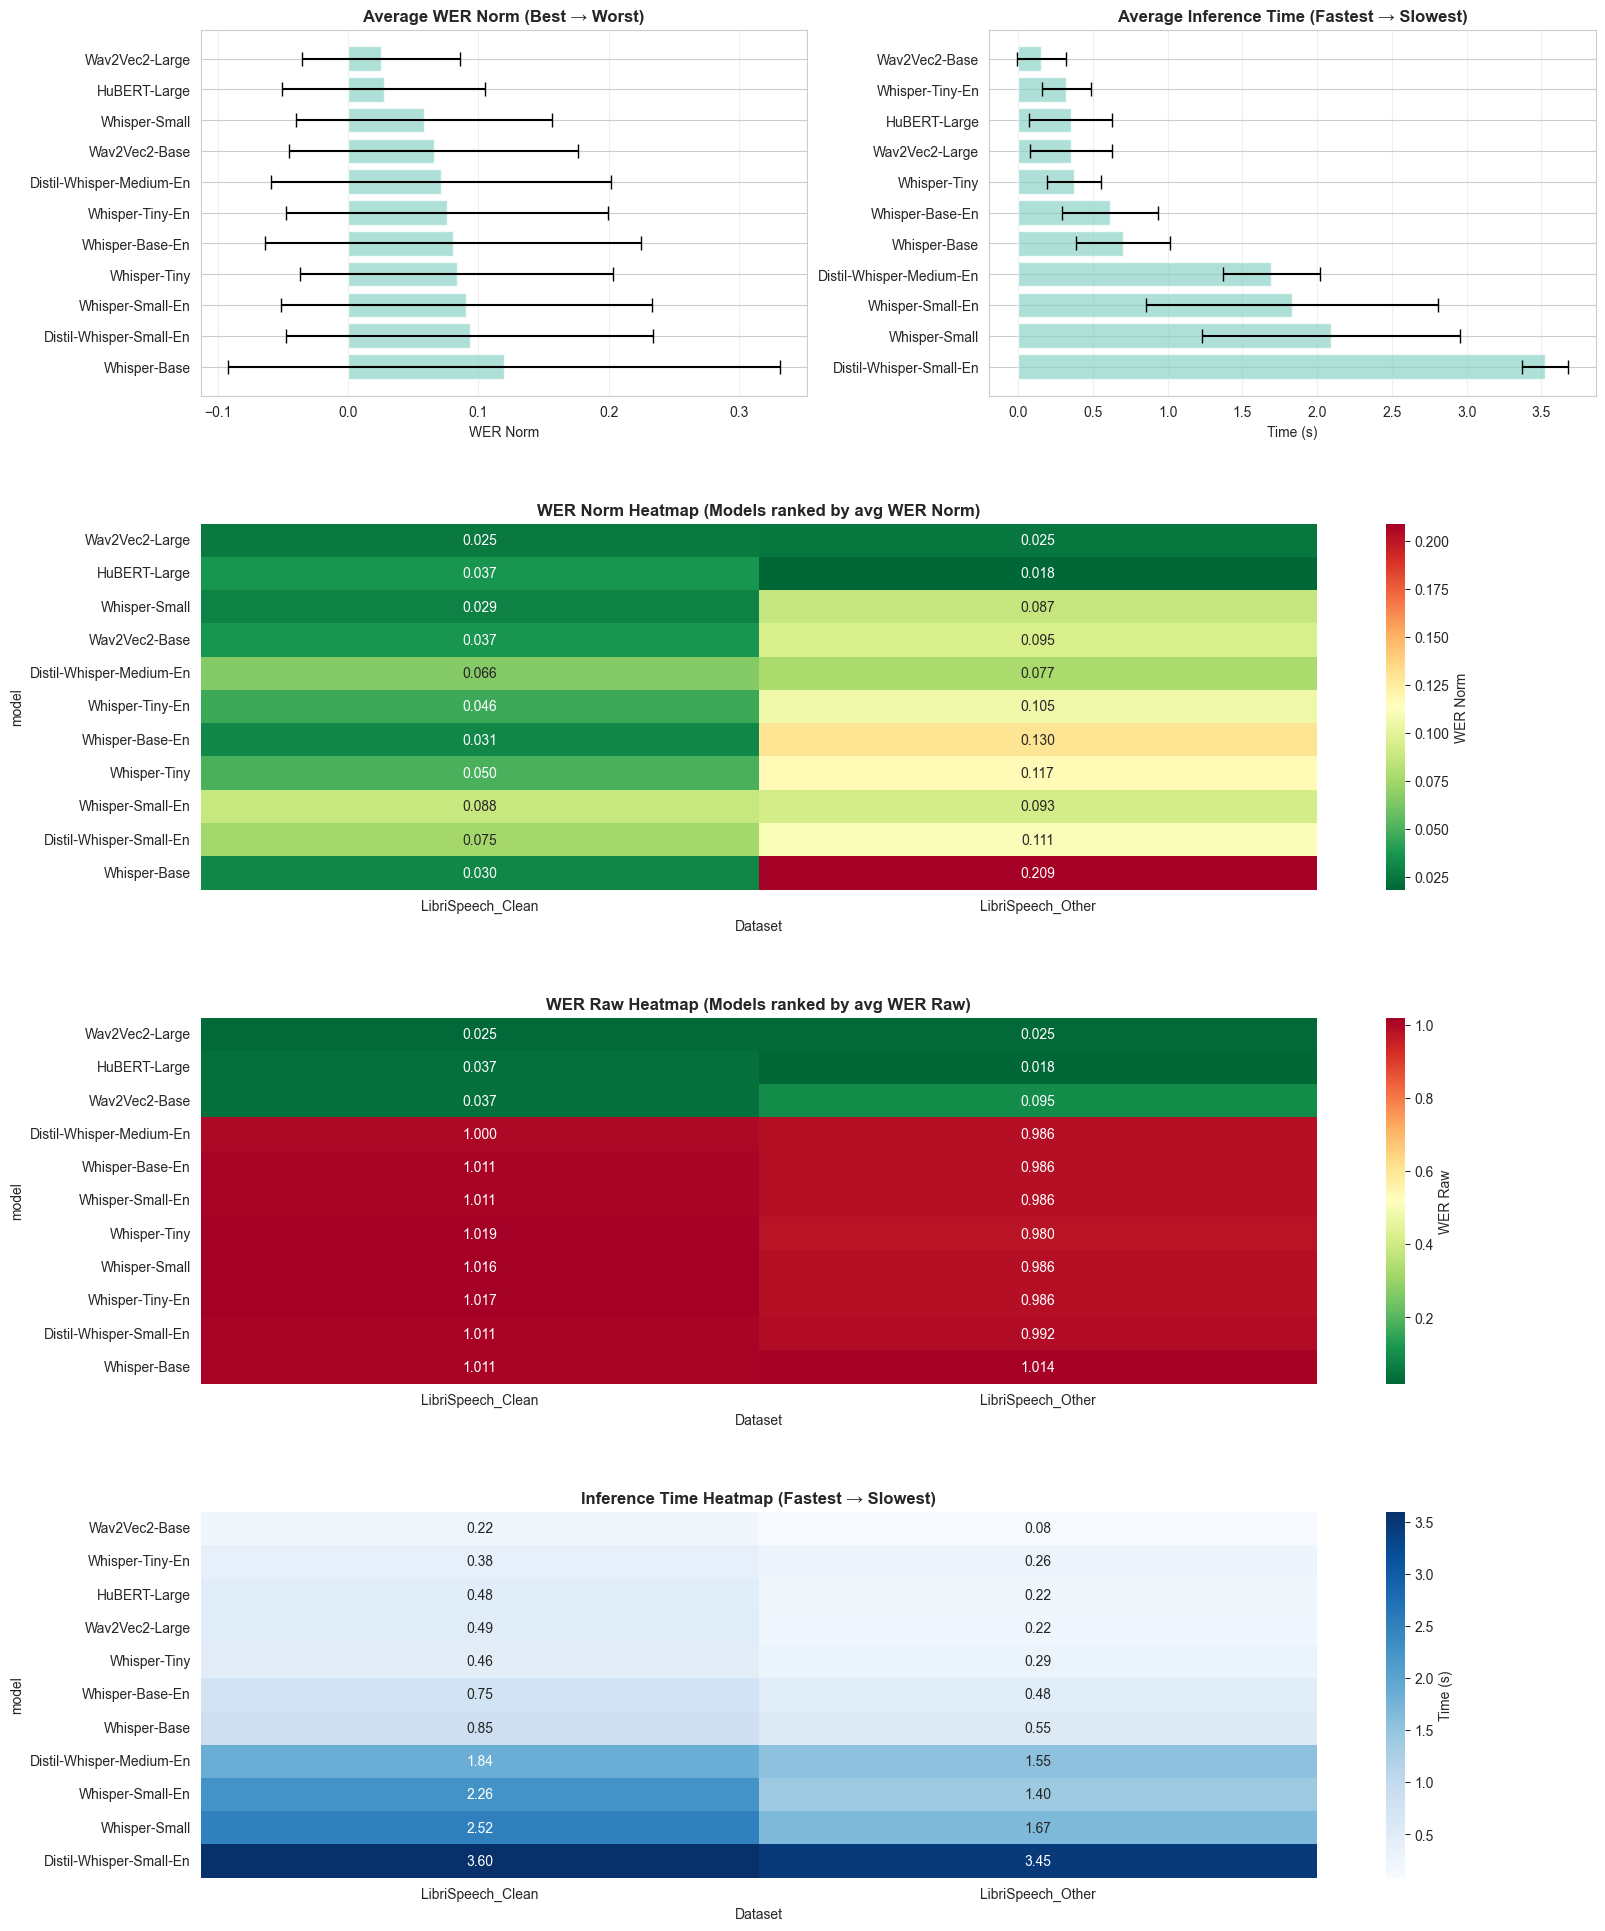

In [66]:
analyzer.plot_comparison(df)

#### 3. Detailed Results Table

In [ ]:
# Show full results table with reference and transcript
display(HTML("<h5>📋 Complete Results</h5>"))

# Create a styled dataframe with better formatting
styled_df = df[['model', 'dataset', 'reference', 'transcript', 'wer', 'time_s']].style \
    .background_gradient(cmap='RdYlGn_r', subset=['wer']) \
    .format({'wer': '{:.3f}', 'time_s': '{:.2f}'}) \
    .set_properties(**{
    'text-align': 'left',
    'white-space': 'pre-wrap',
    'max-width': '300px'
}, subset=['reference', 'transcript']) \
    .set_table_styles([
    {'selector': 'th', 'props': [('text-align', 'left'), ('font-weight', 'bold')]},
    {'selector': 'td', 'props': [('padding', '8px')]}
])

display(styled_df)

#### 4. Save Results

In [ ]:
# Create output directory if it doesn't exist
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save complete results
output_path = os.path.join(OUTPUT_DIR, "asr_results.csv")
df.to_csv(output_path, index=False)
print(f"💾 Results saved to: {output_path}")

# Save summary by model and dataset
summary_path = os.path.join(OUTPUT_DIR, "asr_summary.csv")
summary_df = df.groupby(['model', 'dataset', 'language']).agg({
    'wer': ['mean', 'std', 'min', 'max'],
    'time_s': ['mean', 'std']
}).round(3)
summary_df.to_csv(summary_path)
print(f"💾 Summary saved to: {summary_path}")

print(f"\n📁 All outputs saved to: {OUTPUT_DIR}")